# Basic shapes

Make some polygons, stick them on the grid.

## Code setup

In [1]:
import numpy as np
import matplotlib.patches
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import geojson
import geopandas as gpd
import shapely.geometry
import shapely.plotting
from shapely import Polygon

# Add path to package:
import sys
sys.path.insert(0,'../')
import isopods.grid
import isopods.stick
import isopods.convert

## Define grid

Each grid cell is 0.5 units wide and 0.5 units tall. The grid starts at (0, 9) and is 16 units wide and 9 units tall, ending at (16.5, -0.5). We define the grid from the top left corner (xmin, ymax) to match convention.

In [2]:
# Prepare some variables
cell_size = 0.5
bbox = (0, 0, 16, 9)
transform_dict = isopods.grid.make_transform_dict(bbox, cell_size, cell_size)

In [3]:
transform_dict

{'xmin': 0,
 'ymax': 9,
 'cell_width': 0.5,
 'cell_height': 0.5,
 'n_cols': 32,
 'n_rows': 18,
 'xmax': 16.0,
 'ymin': 0.0}

The grid will cover this extent:

In [4]:
extent = (transform_dict['xmin'], transform_dict['xmax'],
          transform_dict['ymin'], transform_dict['ymax'])

Setup for plot based on this grid:

In [5]:
def plot_grid(ax, td):
    """td is transform_dict"""
    ax.xaxis.set_major_locator(ticker.MultipleLocator(2*td['cell_width'], offset=td['xmin']))
    ax.xaxis.set_minor_locator(ticker.MultipleLocator(td['cell_width'], offset=td['xmin']))
    
    ax.yaxis.set_major_locator(ticker.MultipleLocator(2*td['cell_height'], offset=td['ymin']))
    ax.yaxis.set_minor_locator(ticker.MultipleLocator(td['cell_height'], offset=td['ymin']))
    ax.grid(which='both')
    
    ax.set_xlim(td['xmin'], td['xmax'])
    ax.set_ylim(td['ymin'], td['ymax'])
    ax.set_aspect('equal')

## Define generic shapes

In [6]:
def coords_from_poly(p):
    return p.get_verts()

In [7]:
# Dict of shapes. Circles with centre (x, y) then radius.
dict_polys = dict(
    c = {'patch': matplotlib.patches.CirclePolygon((2, 2), 3),
         'value': 1,},
    d = {'patch': matplotlib.patches.CirclePolygon((8, 6), 4),
         'value': 2,},
    e = {'patch': matplotlib.patches.CirclePolygon((12.5, 2), 2),
         'value': 3,},
    f = {'patch': matplotlib.patches.CirclePolygon((14, 7), 1.5),
         'value': 1,},
    g = {'patch': matplotlib.patches.CirclePolygon((13, 8), 1),
         'value': 3,},
)
for label, d in dict_polys.items():
    dict_polys[label]['poly'] = Polygon(coords_from_poly(d['patch']))

Set up some formatting for the plots. Which colour should be assigned to each value? Then match the colours to the circles with that value.

In [8]:
# Colours are RGB tuples.
dict_colours = dict([
    (1, (1.0, 0.0, 0.0, 0.5)),  # red
    (2, (0.0, 1.0, 0.0, 0.5)),  # green
    (3, (0.0, 0.0, 1.0, 0.5)),  # blue
])

for label, d in dict_polys.items():
    colour = dict_colours[d['value']]
    dict_polys[label]['kwargs'] = dict(facecolor=colour, edgecolor='k')

Convert to geodataframe. First convert to a geojson FeatureCollection.

In [9]:
features = []
for label, d in dict_polys.items():
    f = geojson.Feature(geometry=shapely.geometry.mapping(d['poly']),
                        properties={'label': label})
    features.append(f)

fc = geojson.FeatureCollection(features)

gdf = gpd.GeoDataFrame.from_features(fc).set_index('label')

Check whether any shapes overlap:

In [10]:
pairs = isopods.stick.find_overlapping_polygons(gdf)
print(f'Pairs of overlapping shapes: {pairs}')

Pairs of overlapping shapes: ['f' 'g']


Here two of the circles overlap. In this case we'll remove the overlapping area by letting only one circle occupy that area. The other polygon will become a crescent.

In [11]:
# Update the geopandas series:
gdf.loc[['g']] = gdf.loc[['g']].difference(gdf.loc[['f']], align=False)
gdf.loc[['f']] = gdf.loc[['f']].difference(gdf.loc[['g']], align=False)
# Update the original polygon:
dict_polys['g']['poly'] = gdf.loc['g', 'geometry']
dict_polys['f']['poly'] = gdf.loc['f', 'geometry']

Check that there are no more overlaps:

In [12]:
pairs = isopods.stick.find_overlapping_polygons(gdf)
print(f'Pairs of overlapping shapes: {pairs}')

Pairs of overlapping shapes: []


## Plot generic shapes on grid

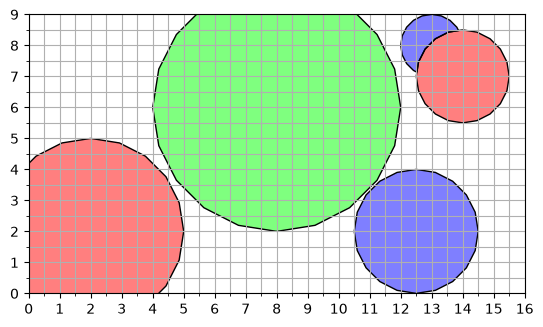

In [13]:
fig, ax = plt.subplots()

for label, d in dict_polys.items():
    # Convert polygon to a matplotlib patch:
    p = shapely.plotting.patch_from_polygon(d['poly'], **d['kwargs'])
    # Draw patch:
    ax.add_patch(p)

plot_grid(ax, transform_dict)
plt.show()

Note that we draw these polygons in translucent colours to check for overlapping objects. Here we can see no outlines of any one shape passing through another, so no objects are overlapping.

## Stick shapes to the grid

In [14]:
df_props = isopods.stick.stick_shapes_to_grid(
    gdf, **transform_dict, print_progress=True)

100.0% of cells checked

Check the results for the first few cells that contain any shapes:

In [15]:
df_props.head(3)

,cell_row,cell_col,label_props,area_props,prop_cell_covered,label_majority,overlapping_polys
cell_label,,,,,,,
0,0,0,[c],[1.0],1.0,c,0
1,1,0,[c],[1.0],1.0,c,0
2,2,0,[c],[1.0],1.0,c,0


Pick out some cells containing multiple shapes:

In [16]:
mask = df_props['label_props'].str.len() > 1
df_props[mask].head()

,cell_row,cell_col,label_props,area_props,prop_cell_covered,label_majority,overlapping_polys
cell_label,,,,,,,
152,8,8,"[d, c]","[0.609, 0.391]",0.186,d,0
168,6,9,"[c, d]","[0.961, 0.039]",0.392,c,0
169,7,9,"[d, c]","[0.974, 0.026]",0.568,d,0
383,5,21,"[e, d]","[0.977, 0.023]",0.675,e,0
384,6,21,"[d, e]","[0.823, 0.177]",0.801,d,0


## Convert dataframe to 2D grid

Can either run this to find the labels of the shape in each cell...

In [17]:
arr_labels = isopods.convert.convert_df_to_2darray(df_props, 'label_majority', **transform_dict)

In [18]:
arr_labels.shape

(18, 32)

In [19]:
arr_labels[:2]

masked_array(
  data=[['c', 'c', 'c', 'c', 'c', 'c', 'c', 'c', 'c', 'c', --, --, --,
         --, --, --, --, --, --, --, --, --, 'e', 'e', 'e', 'e', 'e',
         'e', --, --, --, --],
        ['c', 'c', 'c', 'c', 'c', 'c', 'c', 'c', 'c', 'c', --, --, --,
         --, --, --, --, --, --, --, --, 'e', 'e', 'e', 'e', 'e', 'e',
         'e', 'e', --, --, --]],
  mask=[[False, False, False, False, False, False, False, False, False,
         False,  True,  True,  True,  True,  True,  True,  True,  True,
          True,  True,  True,  True, False, False, False, False, False,
         False,  True,  True,  True,  True],
        [False, False, False, False, False, False, False, False, False,
         False,  True,  True,  True,  True,  True,  True,  True,  True,
          True,  True,  True, False, False, False, False, False, False,
         False, False,  True,  True,  True]],
  fill_value=np.str_('?'),
  dtype=object)

In [20]:
arr_labels.data[:2]

array([['c', 'c', 'c', 'c', 'c', 'c', 'c', 'c', 'c', 'c', '', '', '', '',
        '', '', '', '', '', '', '', '', 'e', 'e', 'e', 'e', 'e', 'e', '',
        '', '', ''],
       ['c', 'c', 'c', 'c', 'c', 'c', 'c', 'c', 'c', 'c', '', '', '', '',
        '', '', '', '', '', '', '', 'e', 'e', 'e', 'e', 'e', 'e', 'e',
        'e', '', '', '']], dtype=object)

In [21]:
arr_labels.mask[:2]

array([[False, False, False, False, False, False, False, False, False,
        False,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True,  True, False, False, False, False, False,
        False,  True,  True,  True,  True],
       [False, False, False, False, False, False, False, False, False,
        False,  True,  True,  True,  True,  True,  True,  True,  True,
         True,  True,  True, False, False, False, False, False, False,
        False, False,  True,  True,  True]])

... or first create another column containing some data.

In [22]:
dict_label_to_value = dict(zip(
    dict_polys.keys(), [d['value'] for d in dict_polys.values()]))
dict_label_to_value

{'c': 1, 'd': 2, 'e': 3, 'f': 1, 'g': 3}

In [23]:
df_props['value'] = df_props['label_majority'].map(dict_label_to_value)

In [24]:
arr_values = isopods.convert.convert_df_to_2darray(
    df_props, 'value', **transform_dict)

In [25]:
arr_values[:2]

masked_array(
  data=[[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, --, --, --, --, --, --, --, --,
         --, --, --, --, 3, 3, 3, 3, 3, 3, --, --, --, --],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, --, --, --, --, --, --, --, --,
         --, --, --, 3, 3, 3, 3, 3, 3, 3, 3, --, --, --]],
  mask=[[False, False, False, False, False, False, False, False, False,
         False,  True,  True,  True,  True,  True,  True,  True,  True,
          True,  True,  True,  True, False, False, False, False, False,
         False,  True,  True,  True,  True],
        [False, False, False, False, False, False, False, False, False,
         False,  True,  True,  True,  True,  True,  True,  True,  True,
          True,  True,  True, False, False, False, False, False, False,
         False, False,  True,  True,  True]],
  fill_value=999999)

Convert values to colours:

In [26]:
dict_colours

{1: (1.0, 0.0, 0.0, 0.5), 2: (0.0, 1.0, 0.0, 0.5), 3: (0.0, 0.0, 1.0, 0.5)}

In [27]:
arr_colours = isopods.convert.convert_grid_values(arr_values, dict_colours)

In [28]:
arr_colours.shape

(18, 32, 4)

Check colours of the first couple of cells:

In [29]:
arr_colours[:2, 0, :]

masked_array(
  data=[[1.0, 0.0, 0.0, 0.5],
        [1.0, 0.0, 0.0, 0.5]],
  mask=[[False, False, False, False],
        [False, False, False, False]],
  fill_value=1e+20)

## Plot 2D grid

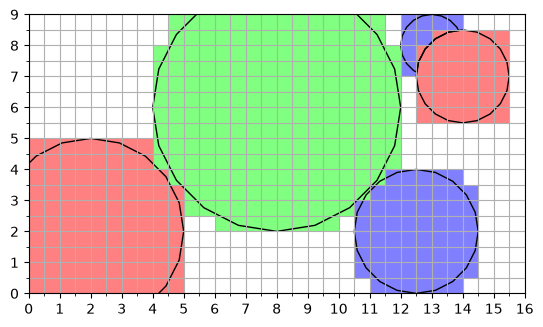

In [30]:
fig, ax = plt.subplots()

ax.imshow(arr_colours, origin='lower', extent=extent)

# Overlay the original circles:
for label, d in dict_polys.items():
    # Convert polygon to a matplotlib patch:
    p = shapely.plotting.patch_from_polygon(
        d['poly'], facecolor=(0, 0, 0, 0), edgecolor='k')
    ax.add_patch(p)

plot_grid(ax, transform_dict)
plt.show()

## Only include mostly-full cells

In [31]:
df_props.head(2)

,cell_row,cell_col,label_props,area_props,prop_cell_covered,label_majority,overlapping_polys,value
cell_label,,,,,,,,
0,0,0,[c],[1.0],1.0,c,0,1
1,1,0,[c],[1.0],1.0,c,0,1


In [32]:
mask = df_props['prop_cell_covered'] >= 0.5
arr_values_covered = isopods.convert.convert_df_to_2darray(
    df_props.loc[mask], 'value', **transform_dict)
arr_colours_covered = isopods.convert.convert_grid_values(
    arr_values_covered, dict_colours)

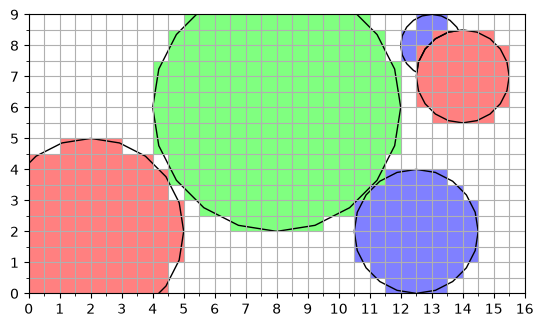

In [33]:
fig, ax = plt.subplots()

ax.imshow(arr_colours_covered, origin='lower', extent=extent)

# Overlay the original circles:
for label, d in dict_polys.items():
    # Convert polygon to a matplotlib patch:
    p = shapely.plotting.patch_from_polygon(
        d['poly'], facecolor=(0, 0, 0, 0), edgecolor='k')
    ax.add_patch(p)

plot_grid(ax, transform_dict)
plt.show()